# HW4 — Four-cohort portfolio backtest

This notebook converts the stored out-of-sample scores into a long-only, self-financing portfolio. Model fitting and score construction were completed in the previous notebook.

Four cohorts are initially started 15 market sessions apart. At each entry, we select up to 50 stocks using scores formed at the previous market close. A cohort can invest at most one quarter of the previous-close portfolio NAV, limited by cash already available at that close. The fee-inclusive budget is split equally among the selected stocks.

Each purchase is an independent lot scheduled to exit 60 market sessions after entry. Once a cohort's scheduled lots reach maturity, it can plan its next entry for the following session. If a planned entry has no score, available cash, or executable quote, that cohort skips a 61-session round instead of joining other cohorts in a shared daily retry. A lot without a valid exit quote remains open separately; other completed sales may be reinvested.

Purchases and sales use observed adjusted closing prices. We charge 5 basis points of traded notional on each side, pay no interest on cash, and never borrow. The test runs from the first scored test signal in 2007 through September 30, 2026. We compare the portfolio with $1,000,000 invested in the supplied `^SP500TR` benchmark at the first test close.

The separate lot and cash accounting follows the approach demonstrated in `Lectures/modeling/backtest.py`.

In [7]:
from pathlib import Path
import gc

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "Lectures/modeling/data/equities_top2000.duckdb").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Missing Lectures/modeling/data/equities_top2000.duckdb")

RAW_DB = ROOT / "Lectures/modeling/data/equities_top2000.duckdb"
MODEL_DIR = ROOT / "Homeworks/HW4/Yisu_Wang/outputs/rolling_lgbm_ic_v5_top4_60_sessions"
FIRST_MODEL_YEAR = 2007
END = pd.Timestamp("2026-09-30")
INITIAL_CASH, TOP_N, COHORT_FRACTION = 1_000_000.0, 50, 1 / 4
HOLD_SESSIONS, REBALANCE_SESSIONS = 60, 15
FEE_BPS, MAX_STALE_SESSIONS = 5.0, 5
FEE_RATE = FEE_BPS / 10_000

score_files = [
    MODEL_DIR / str(year) / "signal_scores.parquet"
    for year in range(FIRST_MODEL_YEAR, END.year + 1)
]
missing_files = [str(path) for path in score_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing yearly score files: {missing_files}")

with duckdb.connect(str(RAW_DB), read_only=True) as db:
    first_signal = db.execute("""
        SELECT MIN(PRICE_date) FROM read_parquet(?)
    """, [str(score_files[0])]).fetchone()[0]
    calendar = pd.DatetimeIndex(pd.to_datetime(
        db.execute("SELECT date FROM calendar ORDER BY date").fetchdf()["date"]
    ))
    benchmark = db.execute("""
        SELECT date, adj_close FROM benchmark
        WHERE symbol = '^SP500TR' ORDER BY date
    """).fetchdf()

if first_signal is None:
    raise ValueError("The first model year has no scored test signals")
START = pd.Timestamp(first_signal)
benchmark["date"] = pd.to_datetime(benchmark["date"])
test_days = calendar[(calendar >= START) & (calendar <= END)]

if (not len(test_days) or test_days[0] != START
        or test_days[-1] != END or calendar.get_loc(START) == 0):
    raise ValueError("The market calendar does not cover the complete test interval")
if calendar.has_duplicates or benchmark.date.duplicated().any():
    raise ValueError("The calendar or benchmark has duplicate dates")

benchmark = benchmark.set_index("date")["adj_close"].reindex(test_days)
if benchmark.isna().any() or not (np.isfinite(benchmark) & benchmark.gt(0)).all():
    raise ValueError("The benchmark needs a valid quote on every test session")

calendar_pos = {day: i for i, day in enumerate(calendar)}
print("First scored test signal:", START.date())
print("Test end:", END.date())
print("Test sessions:", len(test_days))
print("Fee per side (bps):", FEE_BPS)

First scored test signal: 2007-01-03
Test end: 2026-09-30
Test sessions: 4967
Fee per side (bps): 5.0


## 1. Establish the initial four entry dates

Find the first eligible entry date in the first score file. This date anchors four initial entry opportunities, separated by 15 dates in the supplied market-session calendar.

These dates only establish the first entry for each cohort. A later entry follows that cohort's actual maturity and available cash. If an entry attempt has no score, cash, or executable quote, that cohort skips this round and tries again 61 market sessions later. Its missing signal must not pull the other cohorts into the same entry date. Successful entries normally follow the previous lot's maturity on the next market session.

In [8]:
with duckdb.connect(str(RAW_DB), read_only=True) as db:
    anchor = db.execute("""
        SELECT MIN(ENTRY_date) FROM read_parquet(?)
        WHERE ENTRY_date >= ? AND ENTRY_date <= ?
    """, [str(score_files[0]), START, END]).fetchone()[0]

if anchor is None:
    raise ValueError("No eligible entry found in the first score file")
anchor = pd.Timestamp(anchor)
if anchor not in calendar_pos:
    raise ValueError(f"First scored entry is absent from the calendar: {anchor}")

initial_indices = [calendar_pos[anchor] + i * REBALANCE_SESSIONS for i in range(4)]
if initial_indices[-1] > calendar_pos[END]:
    raise ValueError("The test interval does not cover the four initial entries")

initial_schedule = pd.DataFrame({
    "slot_id": range(1, 5),
    "first_entry": calendar[initial_indices]
})
display(initial_schedule)

,slot_id,first_entry
0,1,2007-01-04
1,2,2007-01-26
2,3,2007-02-16
3,4,2007-03-12


## 2. Execution and missing-price policy

Before an entry session, use only the previous session's scores, cash, and NAV to select up to 50 stocks and plan a fee-inclusive budget. Entry-day prices are not used to select stocks or set that budget. An entry order without a valid observed adjusted close is cancelled, leaving its allocation in cash.

A purchased lot becomes due 60 market sessions after entry. If it has a valid observed quote on or after maturity, sell it at that close. Otherwise, retain it as an open position and wait for its next observed valid quote. No sale proceeds are credited before an actual sale.

Once the lots in a cohort reach maturity, the cohort may attempt another entry on the following market session. A failed entry attempt skips one 61-session round; it does not retry daily and synchronize all cohorts after a shared gap in scores. Lots still awaiting a quote remain open separately. Other lots' actual sale proceeds are available to the next entry; an unresolved lot never supplies spendable cash.

For the first five missing market sessions, use a holding's last observed quote as a daily valuation mark. From the sixth missing session onward, keep the last observed mark only as a clearly provisional accounting value and record that holding's unresolved value separately. Never use a carried mark as a trade fill. If a valid quote returns, update the mark and execute any overdue sale.

This policy uses information observed by each simulated date. The absence of a new price does not reveal whether the stock will resume trading or what a possible corporate-action payment might be.

In [9]:
def candidates_for_entry(db, day, signal_day):
    file = MODEL_DIR / str(signal_day.year) / "signal_scores.parquet"
    if not file.is_file():
        raise FileNotFoundError(file)
    candidates = db.execute("""
        SELECT PRICE_symbol, PRICE_date, ENTRY_date, scheduled_exit, score, model_year
        FROM read_parquet(?) WHERE PRICE_date = ? AND ENTRY_date = ?
        ORDER BY score DESC, PRICE_symbol ASC LIMIT ?
    """, [str(file), signal_day, day, TOP_N]).fetchdf()
    if candidates.empty:
        return candidates

    for col in ("PRICE_date", "ENTRY_date", "scheduled_exit"):
        candidates[col] = pd.to_datetime(candidates[col])
    if (candidates["PRICE_symbol"].duplicated().any()
            or not candidates["PRICE_date"].eq(signal_day).all()
            or not candidates["ENTRY_date"].eq(day).all()
            or not candidates["model_year"].eq(signal_day.year).all()
            or not np.isfinite(candidates["score"]).all()):
        raise ValueError(f"Invalid scores for entry {day.date()}")
    return candidates


def year_quotes(db, year):
    frame = db.execute("""
        SELECT date, symbol, adj_close FROM prices
        WHERE date >= ? AND date < ?
    """, [f"{year}-01-01", f"{year + 1}-01-01"]).fetchdf()
    frame["date"] = pd.to_datetime(frame["date"])
    if frame.duplicated(["date", "symbol"]).any():
        raise ValueError(f"Duplicate price keys in {year}")

    invalid = ~np.isfinite(frame["adj_close"]) | frame["adj_close"].le(0)
    print(year, "invalid price rows excluded:", int(invalid.sum()))
    frame = frame.loc[~invalid]
    by_day = {date: group.set_index("symbol")["adj_close"]
              for date, group in frame.groupby("date", sort=False)}
    del frame
    gc.collect()
    return by_day


def run_backtest():
    cash, lots, marks, last_seen = INITIAL_CASH, {}, {}, {}
    slots = [{"slot_id": i + 1, "next_entry_index": index, "lot_ids": set()}
             for i, index in enumerate(initial_indices)]
    fills, events, history = [], [], []
    next_lot_id = 1

    initial_date = calendar[calendar_pos[START] - 1]
    history.append({
        "date": initial_date, "cash": cash, "holdings_value": 0.0,
        "nav": cash, "open_lots": 0, "fees": 0.0,
        "gross_traded": 0.0, "stale_marks": 0,
        "unresolved_lots": 0, "unresolved_value": 0.0,
        "planned_cohort_budget": 0.0, "actual_buy_spend": 0.0
    })

    with duckdb.connect(str(RAW_DB), read_only=True) as db:
        for year in range(START.year, END.year + 1):
            quotes = year_quotes(db, year)
            for day in test_days[test_days.year == year]:
                day_index = calendar_pos[day]
                signal_day = calendar[day_index - 1]
                prior_nav = cash + sum(lot["units"] * marks[lot["symbol"]]
                                       for lot in lots.values())
                plans, reserved_cash = [], cash

                # Plan entries using only the previous close.
                for slot in slots:
                    if slot["next_entry_index"] != day_index:
                        continue
                    candidates = candidates_for_entry(db, day, signal_day)
                    if candidates.empty:
                        slot["next_entry_index"] = day_index + HOLD_SESSIONS + 1
                        events.append({
                            "date": day, "slot_id": slot["slot_id"],
                            "symbol": None, "event": "no_signal", "sessions": 0
                        })
                        continue
                    budget = min(COHORT_FRACTION * prior_nav, reserved_cash)
                    reserved_cash -= budget
                    plans.append((slot, candidates, budget))

                # Read today's actual quotes and update held-position marks.
                observed = quotes.get(day, pd.Series(dtype="float64"))
                held_symbols = {lot["symbol"] for lot in lots.values()}
                stale = 0
                for symbol in held_symbols:
                    if symbol in observed.index:
                        missing_sessions = day_index - last_seen[symbol] - 1
                        if missing_sessions > MAX_STALE_SESSIONS:
                            events.append({
                                "date": day, "slot_id": None,
                                "symbol": symbol, "event": "quote_resumed",
                                "sessions": missing_sessions
                            })
                        marks[symbol], last_seen[symbol] = float(observed[symbol]), day_index
                    else:
                        gap = day_index - last_seen[symbol]
                        stale += 1
                        if gap == MAX_STALE_SESSIONS + 1:
                            events.append({
                                "date": day, "slot_id": None, "symbol": symbol,
                                "event": "unresolved_price", "sessions": gap
                            })
                        elif gap <= MAX_STALE_SESSIONS:
                            events.append({
                                "date": day, "slot_id": None, "symbol": symbol,
                                "event": "stale_mark", "sessions": gap
                            })

                # Sell mature lots only when an actual valid quote exists.
                fill_start = len(fills)
                for lot_id, lot in list(lots.items()):
                    if day_index < lot["exit_index"]:
                        continue
                    symbol = lot["symbol"]
                    slot = slots[lot["slot_id"] - 1]
                    slot["lot_ids"].discard(lot_id)
                    if not slot["lot_ids"] and slot["next_entry_index"] is None:
                        slot["next_entry_index"] = day_index + 1

                    if symbol not in observed.index:
                        if day_index == lot["exit_index"]:
                            events.append({
                                "date": day, "slot_id": lot["slot_id"],
                                "symbol": symbol, "event": "exit_waiting_quote",
                                "sessions": 0
                            })
                        continue

                    price, units = float(observed[symbol]), lot["units"]
                    notional, fee = units * price, units * price * FEE_RATE
                    cash_change = notional - fee
                    cash += cash_change
                    pnl = cash_change - units * lot["entry_price"] - lot["entry_fee"]
                    fills.append({
                        "date": day, "signal_date": lot["signal_date"],
                        "slot_id": lot["slot_id"], "lot_id": lot_id,
                        "symbol": symbol, "side": "SELL", "price": price,
                        "units": units, "notional": notional, "fee": fee,
                        "cash_change": cash_change,
                        "scheduled_exit": lot["scheduled_exit"],
                        "realized_pnl": pnl, "score": lot["score"],
                        "model_year": lot["model_year"]
                    })
                    del lots[lot_id]

                # Execute orders against the planned budget and actual cash.
                for slot, candidates, budget in plans:
                    spendable = min(budget, cash)
                    if spendable <= 1e-7:
                        slot["next_entry_index"] = day_index + HOLD_SESSIONS + 1
                        events.append({
                            "date": day, "slot_id": slot["slot_id"],
                            "symbol": None, "event": "waiting_cash", "sessions": 0
                        })
                        continue

                    per_name = spendable / len(candidates)
                    for row in candidates.itertuples(index=False):
                        symbol = row.PRICE_symbol
                        if symbol not in observed.index:
                            events.append({
                                "date": day, "slot_id": slot["slot_id"],
                                "symbol": symbol, "event": "entry_missing_quote",
                                "sessions": 0
                            })
                            continue

                        exit_index = day_index + HOLD_SESSIONS
                        if exit_index < len(calendar):
                            if calendar[exit_index] != row.scheduled_exit:
                                raise ValueError(
                                    f"Inconsistent scheduled exit: {symbol} {day.date()}"
                                )
                        elif pd.notna(row.scheduled_exit):
                            raise ValueError(
                                f"Unverifiable scheduled exit: {symbol} {day.date()}"
                            )

                        price = float(observed[symbol])
                        units = per_name / (price * (1 + FEE_RATE))
                        notional, fee = units * price, units * price * FEE_RATE
                        if notional + fee > cash + 1e-7:
                            raise ValueError(
                                f"Insufficient cash for {symbol} on {day.date()}"
                            )

                        cash = max(0.0, cash - notional - fee)
                        lots[next_lot_id] = {
                            "lot_id": next_lot_id, "slot_id": slot["slot_id"],
                            "symbol": symbol, "units": units,
                            "signal_date": signal_day, "entry_date": day,
                            "entry_price": price, "entry_fee": fee,
                            "exit_index": exit_index,
                            "scheduled_exit": row.scheduled_exit,
                            "score": float(row.score),
                            "model_year": row.model_year
                        }
                        slot["lot_ids"].add(next_lot_id)
                        marks[symbol], last_seen[symbol] = price, day_index
                        fills.append({
                            "date": day, "signal_date": signal_day,
                            "slot_id": slot["slot_id"], "lot_id": next_lot_id,
                            "symbol": symbol, "side": "BUY", "price": price,
                            "units": units, "notional": notional, "fee": fee,
                            "cash_change": -(notional + fee),
                            "scheduled_exit": row.scheduled_exit,
                            "realized_pnl": 0.0, "score": float(row.score),
                            "model_year": row.model_year
                        })
                        next_lot_id += 1

                    if slot["lot_ids"]:
                        slot["next_entry_index"] = None
                    else:
                        slot["next_entry_index"] = day_index + HOLD_SESSIONS + 1

                # Record cash and the marked value of open positions.
                holdings_value = sum(lot["units"] * marks[lot["symbol"]]
                                     for lot in lots.values())
                unresolved = [
                    lot for lot in lots.values()
                    if day_index - last_seen[lot["symbol"]] > MAX_STALE_SESSIONS
                ]
                unresolved_value = sum(
                    lot["units"] * marks[lot["symbol"]] for lot in unresolved
                )
                day_fills = fills[fill_start:]
                history.append({
                    "date": day, "cash": cash,
                    "holdings_value": holdings_value,
                    "nav": cash + holdings_value,
                    "open_lots": len(lots),
                    "fees": sum(fill["fee"] for fill in day_fills),
                    "gross_traded": sum(fill["notional"] for fill in day_fills),
                    "stale_marks": stale,
                    "unresolved_lots": len(unresolved),
                    "unresolved_value": unresolved_value,
                    "planned_cohort_budget": sum(plan[2] for plan in plans),
                    "actual_buy_spend": -sum(
                        fill["cash_change"] for fill in day_fills
                        if fill["side"] == "BUY"
                    )
                })
            del quotes
            gc.collect()

    daily = pd.DataFrame(history).set_index("date")
    daily["benchmark_nav"] = INITIAL_CASH
    daily.loc[test_days, "benchmark_nav"] = INITIAL_CASH * benchmark / benchmark.iloc[0]

    trade_columns = [
        "date", "signal_date", "slot_id", "lot_id", "symbol", "side",
        "price", "units", "notional", "fee", "cash_change",
        "scheduled_exit", "realized_pnl", "score", "model_year"
    ]
    trades = pd.DataFrame(fills, columns=trade_columns)
    incidents = pd.DataFrame(
        events, columns=["date", "slot_id", "symbol", "event", "sessions"]
    )
    open_lots = pd.DataFrame(lots.values())
    if not open_lots.empty:
        open_lots["last_mark"] = open_lots["symbol"].map(marks)
        open_lots["market_value"] = open_lots["units"] * open_lots["last_mark"]
        open_lots["mark_age_sessions"] = open_lots["symbol"].map(
            lambda symbol: calendar_pos[END] - last_seen[symbol]
        )
        open_lots["unresolved_price"] = open_lots["mark_age_sessions"].gt(
            MAX_STALE_SESSIONS
        )
    return daily, trades, incidents, open_lots

## 3. Run the backtest and inspect execution

Check a fee-inclusive purchase by hand before running the full history: purchase notional plus its entry fee must equal the allocated budget.

Then display the beginning and end of the daily account, actual fills, missing-price and missing-signal events, and positions still open at the test end. Summarize trading by cohort and date to inspect the sell-then-re-enter sequence. Display days when unresolved positions affect the provisional NAV.

In [10]:
sample_budget, sample_price = 100_000.0, 100.0
sample_units = sample_budget / (sample_price * (1 + FEE_RATE))
sample_fee = sample_units * sample_price * FEE_RATE
sample_spend = sample_units * sample_price + sample_fee
display(pd.Series({
    "budget": sample_budget, "units": sample_units,
    "entry_fee": sample_fee, "cash_spent": sample_spend
}, name="manual_entry"))
if not np.isclose(sample_spend, sample_budget):
    raise ValueError("Fee-inclusive sizing does not reconcile")

daily, trades, incidents, open_lots = run_backtest()
display(daily.head())
display(daily.tail())
display(trades.head(10))
display(
    incidents.groupby("event").size().rename("events").to_frame()
    if not incidents.empty else pd.DataFrame(columns=["events"])
)
display(open_lots.head(10))

cohort_activity = trades.groupby(["slot_id", "date", "side"]).agg(
    stocks=("symbol", "nunique"),
    notional=("notional", "sum")
).reset_index()
display(cohort_activity.head(16))
display(cohort_activity.tail(16))

display(daily.loc[
    daily["unresolved_lots"].gt(0),
    ["unresolved_lots", "unresolved_value", "nav"]
].head(10))
display(
    open_lots.loc[open_lots["unresolved_price"]].head(10)
    if not open_lots.empty else open_lots
)

budget        100000.000000
units            999.500250
entry_fee         49.975012
cash_spent    100000.000000
Name: manual_entry, dtype: float64

2007 invalid price rows excluded: 0
2008 invalid price rows excluded: 0
2009 invalid price rows excluded: 0
2010 invalid price rows excluded: 0
2011 invalid price rows excluded: 0
2012 invalid price rows excluded: 0
2013 invalid price rows excluded: 0
2014 invalid price rows excluded: 0
2015 invalid price rows excluded: 0
2016 invalid price rows excluded: 0
2017 invalid price rows excluded: 0
2018 invalid price rows excluded: 0
2019 invalid price rows excluded: 0
2020 invalid price rows excluded: 0
2021 invalid price rows excluded: 0
2022 invalid price rows excluded: 0
2023 invalid price rows excluded: 0
2024 invalid price rows excluded: 0
2025 invalid price rows excluded: 0
2026 invalid price rows excluded: 0


,cash,holdings_value,nav,open_lots,fees,gross_traded,stale_marks,unresolved_lots,unresolved_value,planned_cohort_budget,actual_buy_spend,benchmark_nav
date,,,,,,,,,,,,
2006-12-29,1000000.0,0.000000,1.000000e+06,0,0.000000,0.000000,0,0,0.0,0.0,0.0,1.000000e+06
2007-01-03,1000000.0,0.000000,1.000000e+06,0,0.000000,0.000000,0,0,0.0,0.0,0.0,1.000000e+06
2007-01-04,750000.0,249875.062469,9.998751e+05,50,124.937531,249875.062469,0,0,0.0,250000.0,250000.0,1.001227e+06
2007-01-05,750000.0,249454.913771,9.994549e+05,50,0.000000,0.000000,0,0,0.0,0.0,0.0,9.951326e+05
2007-01-08,750000.0,251031.041028,1.001031e+06,50,0.000000,0.000000,0,0,0.0,0.0,0.0,9.976556e+05


,cash,holdings_value,nav,open_lots,fees,gross_traded,stale_marks,unresolved_lots,unresolved_value,planned_cohort_budget,actual_buy_spend,benchmark_nav
date,,,,,,,,,,,,
2026-09-24,9.894871e+06,2.246750e+06,1.214162e+07,52,0.0,0.0,29,52,2.246750e+06,0.0,0.0,7.910757e+06
2026-09-25,9.894871e+06,2.246750e+06,1.214162e+07,52,0.0,0.0,29,52,2.246750e+06,0.0,0.0,7.951202e+06
2026-09-28,9.894871e+06,2.246750e+06,1.214162e+07,52,0.0,0.0,29,52,2.246750e+06,0.0,0.0,7.889918e+06
2026-09-29,9.894871e+06,2.246750e+06,1.214162e+07,52,0.0,0.0,29,52,2.246750e+06,0.0,0.0,7.876717e+06
2026-09-30,9.894871e+06,2.246750e+06,1.214162e+07,52,0.0,0.0,29,52,2.246750e+06,0.0,0.0,7.857618e+06


,date,signal_date,slot_id,lot_id,symbol,side,price,units,notional,fee,cash_change,scheduled_exit,realized_pnl,score,model_year
0,2007-01-04,2007-01-03,1,1,NVOS,BUY,102.000000,48.995110,4997.501249,2.498751,-5000.0,2007-04-02,0.0,5.950572,2007
1,2007-01-04,2007-01-03,1,2,CORT,BUY,1.180000,4235.170550,4997.501249,2.498751,-5000.0,2007-04-02,0.0,5.429034,2007
2,2007-01-04,2007-01-03,1,3,CIX,BUY,9.820000,508.910514,4997.501249,2.498751,-5000.0,2007-04-02,0.0,4.958125,2007
3,2007-01-04,2007-01-03,1,4,PFSW,BUY,3.230000,1547.214009,4997.501249,2.498751,-5000.0,2007-04-02,0.0,4.627054,2007
4,2007-01-04,2007-01-03,1,5,UFPT,BUY,5.410000,923.752541,4997.501249,2.498751,-5000.0,2007-04-02,0.0,4.266912,2007
5,2007-01-04,2007-01-03,1,6,EMAN,BUY,1.040524,4802.869755,4997.501249,2.498751,-5000.0,2007-04-02,0.0,4.116776,2007
6,2007-01-04,2007-01-03,1,7,GVP,BUY,71.000000,70.387342,4997.501249,2.498751,-5000.0,2007-04-02,0.0,3.629504,2007
7,2007-01-04,2007-01-03,1,8,IEP,BUY,16.010000,312.148735,4997.501249,2.498751,-5000.0,2007-04-02,0.0,3.379776,2007
8,2007-01-04,2007-01-03,1,9,REPX,BUY,70.240000,71.148936,4997.501249,2.498751,-5000.0,2007-04-02,0.0,3.355108,2007
9,2007-01-04,2007-01-03,1,10,TELL,BUY,10.320000,484.253997,4997.501249,2.498751,-5000.0,2007-04-02,0.0,2.923303,2007


,events
event,
entry_missing_quote,2
exit_waiting_quote,66
no_signal,8
quote_resumed,7
stale_mark,194
unresolved_price,36


,lot_id,slot_id,symbol,units,signal_date,entry_date,entry_price,entry_fee,exit_index,scheduled_exit,score,model_year,last_mark,market_value,mark_age_sessions,unresolved_price
0,8513,3,WSTC,1114.631926,2017-07-18,2017-07-19,23.32,12.996608,4473,2017-10-12,2.557736,2017,23.50,26193.850254,2254,True
1,8557,4,WSTC,1090.211022,2017-08-08,2017-08-09,23.34,12.722763,4488,2017-11-02,2.112566,2017,23.50,25619.959016,2254,True
2,8706,3,GIMO,761.072941,2017-10-12,2017-10-13,36.25,13.794447,4534,2018-01-10,3.223783,2017,38.50,29301.308227,2201,True
3,11692,2,WORK,1356.117102,2021-05-12,2021-05-13,40.78,27.651228,5434,2021-08-09,2.198449,2021,45.20,61296.493017,1305,True
4,11795,4,PFPT,383.458152,2021-06-24,2021-06-25,173.37,33.240070,5464,2021-09-21,1.596866,2021,175.90,67450.288911,1276,True
5,11837,1,FEYE,2799.716381,2021-07-19,2021-07-20,20.52,28.725090,5480,2021-10-13,2.098293,2021,17.27,48351.101903,1252,True
6,11847,1,PFPT,329.001146,2021-07-19,2021-07-20,174.62,28.725090,5480,2021-10-13,1.515569,2021,175.90,57871.301609,1276,True
7,11883,2,FEYE,3531.883276,2021-08-09,2021-08-10,17.87,31.557377,5495,2021-11-03,2.248602,2021,17.27,60995.624170,1252,True
8,11926,3,FEYE,3491.408410,2021-08-30,2021-08-31,18.19,31.754359,5510,2021-11-24,2.425562,2021,17.27,60296.623246,1252,True
9,11974,4,UFS,1155.940866,2021-09-21,2021-09-22,54.83,31.690119,5525,2021-12-16,2.426738,2021,55.49,64143.158678,1213,True


,slot_id,date,side,stocks,notional
0,1,2007-01-04,BUY,50,249875.062469
1,1,2007-04-02,SELL,50,269785.869027
2,1,2007-04-03,BUY,50,258315.942016
3,1,2007-06-28,SELL,50,276475.535078
4,1,2007-06-29,BUY,50,276448.053217
5,1,2007-09-25,SELL,50,289155.539629
6,1,2007-09-26,BUY,50,282891.155610
7,1,2007-12-20,SELL,50,269692.601431
8,1,2007-12-21,BUY,50,271091.889634
9,1,2008-03-20,SELL,50,216900.608140


,slot_id,date,side,stocks,notional
634,4,2024-11-14,SELL,50,1.866441e+06
635,4,2024-11-15,BUY,50,2.066574e+06
636,4,2025-02-13,SELL,1,8.547531e+03
637,4,2025-02-14,SELL,49,2.042949e+06
638,4,2025-02-18,BUY,50,2.070934e+06
639,4,2025-05-14,SELL,49,1.994323e+06
640,4,2025-05-15,BUY,50,1.992329e+06
641,4,2025-08-12,SELL,49,2.228646e+06
642,4,2025-08-13,BUY,50,2.228490e+06
643,4,2025-11-06,SELL,49,2.338596e+06


,unresolved_lots,unresolved_value,nav
date,,,
2007-11-23,2,11936.265515,1.075038e+06
2007-11-26,2,11936.265515,1.054322e+06
2007-11-27,2,11936.265515,1.059799e+06
2007-11-28,2,11936.265515,1.086008e+06
2007-11-29,2,11936.265515,1.082381e+06
2007-11-30,2,11936.265515,1.101201e+06
2007-12-03,2,11936.265515,1.098186e+06
2007-12-04,2,11936.265515,1.092553e+06
2007-12-05,2,11936.265515,1.085829e+06


,lot_id,slot_id,symbol,units,signal_date,entry_date,entry_price,entry_fee,exit_index,scheduled_exit,score,model_year,last_mark,market_value,mark_age_sessions,unresolved_price
0,8513,3,WSTC,1114.631926,2017-07-18,2017-07-19,23.32,12.996608,4473,2017-10-12,2.557736,2017,23.50,26193.850254,2254,True
1,8557,4,WSTC,1090.211022,2017-08-08,2017-08-09,23.34,12.722763,4488,2017-11-02,2.112566,2017,23.50,25619.959016,2254,True
2,8706,3,GIMO,761.072941,2017-10-12,2017-10-13,36.25,13.794447,4534,2018-01-10,3.223783,2017,38.50,29301.308227,2201,True
3,11692,2,WORK,1356.117102,2021-05-12,2021-05-13,40.78,27.651228,5434,2021-08-09,2.198449,2021,45.20,61296.493017,1305,True
4,11795,4,PFPT,383.458152,2021-06-24,2021-06-25,173.37,33.240070,5464,2021-09-21,1.596866,2021,175.90,67450.288911,1276,True
5,11837,1,FEYE,2799.716381,2021-07-19,2021-07-20,20.52,28.725090,5480,2021-10-13,2.098293,2021,17.27,48351.101903,1252,True
6,11847,1,PFPT,329.001146,2021-07-19,2021-07-20,174.62,28.725090,5480,2021-10-13,1.515569,2021,175.90,57871.301609,1276,True
7,11883,2,FEYE,3531.883276,2021-08-09,2021-08-10,17.87,31.557377,5495,2021-11-03,2.248602,2021,17.27,60995.624170,1252,True
8,11926,3,FEYE,3491.408410,2021-08-30,2021-08-31,18.19,31.754359,5510,2021-11-24,2.425562,2021,17.27,60296.623246,1252,True
9,11974,4,UFS,1155.940866,2021-09-21,2021-09-22,54.83,31.690119,5525,2021-12-16,2.426738,2021,55.49,64143.158678,1213,True


## 4. Check cash, positions, PnL, and timing

Reconstruct daily cash independently from recorded trade cash flows. Verify that NAV equals cash plus marked open positions, cash never becomes negative, purchases follow their signal dates, and sales do not precede their scheduled exits.

Each lot has one purchase and at most one sale. Final NAV minus initial capital must equal realized PnL on sold lots plus unrealized PnL on lots still open, including transaction fees.

This PnL reconciliation checks arithmetic under the stated last-observed-mark convention. It does not establish the executable value of a position whose price remains unresolved.

In [11]:
cash_changes = trades.groupby("date")["cash_change"].sum().reindex(
    test_days, fill_value=0
)
cash_rebuilt = INITIAL_CASH + cash_changes.cumsum()
buys = trades.loc[trades["side"].eq("BUY")]
sells = trades.loc[trades["side"].eq("SELL")]
realized = sells["realized_pnl"].sum()
unrealized = 0.0 if open_lots.empty else (
    open_lots["units"] * (open_lots["last_mark"] - open_lots["entry_price"])
    - open_lots["entry_fee"]
).sum()

checks = pd.Series({
    "one_row_per_test_session": (
        len(daily) == len(test_days) + 1
        and daily.index.is_unique
        and daily.index[0].date() == calendar[calendar_pos[START] - 1].date()
        and np.array_equal(daily.index[1:].date, test_days.date)
    ),
    "cash_matches_fills": np.allclose(
        daily.loc[test_days, "cash"], cash_rebuilt, atol=1e-6
    ),
    "nav_equals_cash_plus_holdings": np.allclose(
        daily["nav"], daily["cash"] + daily["holdings_value"], atol=1e-6
    ),
    "cash_never_negative": daily["cash"].ge(-1e-7).all(),
    "buys_follow_signals": buys["date"].gt(buys["signal_date"]).all(),
    "sells_not_before_due": sells["date"].ge(sells["scheduled_exit"]).all(),
    "each_lot_bought_once": ~buys["lot_id"].duplicated().any(),
    "each_lot_sold_at_most_once": ~sells["lot_id"].duplicated().any(),
    "pnl_reconciles": np.isclose(
        daily["nav"].iloc[-1] - INITIAL_CASH,
        realized + unrealized,
        atol=1e-5
    ),
}, name="passed")
display(checks.to_frame())
if not checks.all():
    raise ValueError("Backtest accounting or timing check failed")

display(pd.Series({
    "realized_pnl": realized,
    "unrealized_pnl": unrealized,
    "net_pnl": daily["nav"].iloc[-1] - INITIAL_CASH,
    "total_fees": trades["fee"].sum(),
    "average_cash_fraction": (
        daily.loc[test_days, "cash"] / daily.loc[test_days, "nav"]
    ).mean(),
    "ending_open_lots": len(open_lots)
}, name="diagnostics").to_frame())

,passed
one_row_per_test_session,True
cash_matches_fills,True
nav_equals_cash_plus_holdings,True
cash_never_negative,True
buys_follow_signals,True
sells_not_before_due,True
each_lot_bought_once,True
each_lot_sold_at_most_once,True
pnl_reconciles,True


,diagnostics
realized_pnl,1.109757e+07
unrealized_pnl,4.404807e+04
net_pnl,1.114162e+07
total_fees,3.956533e+05
average_cash_fraction,4.231094e-02
ending_open_lots,5.200000e+01


## 5. Compare with the benchmark

Both portfolios start with $1,000,000. The benchmark buys `^SP500TR` at the first test close and holds it through the final session. Strategy NAV contains cash and the marked value of positions still open at the test end.

For each portfolio, report final value, total return, calendar-time CAGR, maximum drawdown, and an annualized Sharpe ratio calculated from daily returns using 252 market sessions per year and a 2% annual risk-free rate. Plot both cumulative-return curves from the same initial capital.

The strategy NAV uses last observed prices for holdings without a current quote. Report the number of sessions affected by prices missing for more than five market sessions, the largest unresolved share of NAV, and the unresolved value at the test end. No end-date sale is assumed: cash plus marked open positions is the reported NAV, with long-stale marks separately quantified.

If unresolved positions have a material effect, the performance comparison is provisional. Interpret the observed results only after reviewing these diagnostics.

,valuation_review
sessions_with_unresolved_positions,4.742000e+03
peak_unresolved_fraction_of_nav,1.993052e-01
final_unresolved_lots,5.200000e+01
final_unresolved_value,2.246750e+06


,strategy_provisional,S&P_500_total_return,provisional_minus_benchmark
final_value,1.214162e+07,7.857618e+06,4.284003e+06
total_return,1.114162e+01,6.857618e+00,4.284003e+00
CAGR,1.348231e-01,1.100802e-01,2.474285e-02
max_drawdown,-6.776911e-01,-5.525024e-01,-1.251887e-01
Sharpe,5.080222e-01,5.300668e-01,-2.204459e-02


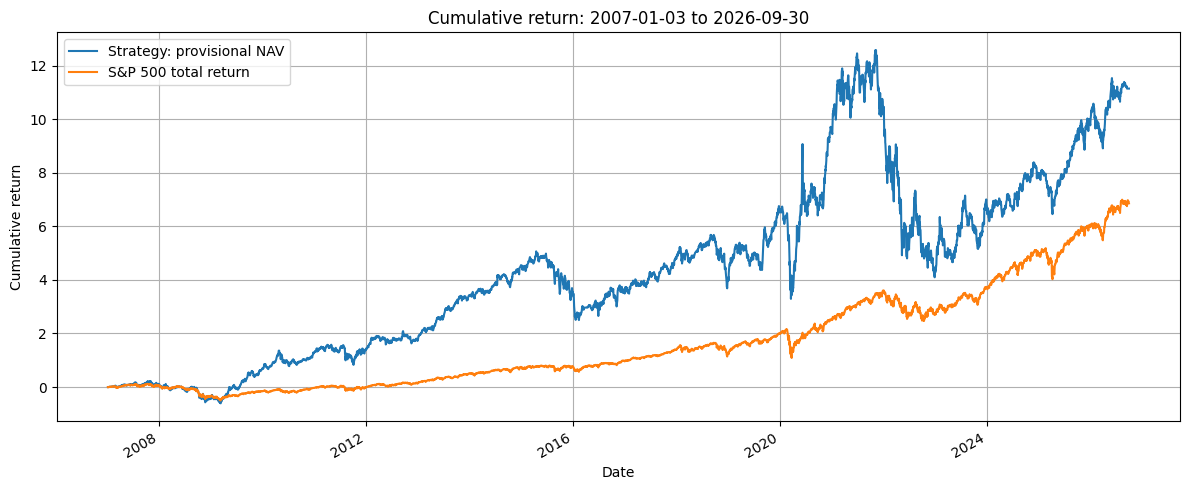

In [12]:
def performance(nav, annual_rf=0.02):
    if not np.isfinite(nav).all() or nav.le(0).any():
        raise ValueError("Daily NAV must be positive and finite")
    returns = nav.pct_change(fill_method=None).dropna()
    years = (nav.index[-1] - START).days / 365.25
    rf_daily = (1 + annual_rf) ** (1 / 252) - 1
    volatility = returns.std(ddof=1)
    return pd.Series({
        "final_value": nav.iloc[-1],
        "total_return": nav.iloc[-1] / INITIAL_CASH - 1,
        "CAGR": (nav.iloc[-1] / INITIAL_CASH) ** (1 / years) - 1,
        "max_drawdown": (nav / nav.cummax() - 1).min(),
        "Sharpe": (
            np.sqrt(252) * (returns - rf_daily).mean() / volatility
            if volatility > 1e-12 else np.nan
        ),
    })

affected = daily.loc[test_days, "unresolved_lots"].gt(0)
valuation_review = pd.Series({
    "sessions_with_unresolved_positions": int(affected.sum()),
    "peak_unresolved_fraction_of_nav": (
        daily.loc[test_days, "unresolved_value"] /
        daily.loc[test_days, "nav"]
    ).max(),
    "final_unresolved_lots": int(daily["unresolved_lots"].iloc[-1]),
    "final_unresolved_value": daily["unresolved_value"].iloc[-1],
}, name="valuation_review")
display(valuation_review.to_frame())

comparison = pd.DataFrame({
    "strategy_provisional": performance(daily["nav"]),
    "S&P_500_total_return": performance(daily["benchmark_nav"]),
})
comparison["provisional_minus_benchmark"] = (
    comparison["strategy_provisional"] -
    comparison["S&P_500_total_return"]
)
display(comparison)

curves = daily.loc[test_days, ["nav", "benchmark_nav"]].rename(
    columns={
        "nav": "Strategy: provisional NAV",
        "benchmark_nav": "S&P 500 total return"
    }
)
ax = curves.div(INITIAL_CASH).sub(1).plot(
    figsize=(12, 5),
    grid=True,
    title=f"Cumulative return: {START.date()} to {END.date()}"
)
ax.set(xlabel="Date", ylabel="Cumulative return")
plt.tight_layout()
plt.show()

## 6. Findings and submission summary

The table and cumulative-return chart above use the same 2007–2026 dates and initial capital. The final open lots are **marked, not liquidated**. A price older than five sessions remains in the NAV at its last observed value, so the result is provisional where those marks are material. The following cell summarizes the actual rerun, checks whether cohort entries collided on the same date, and updates the results paragraph in this folder's `README.md`. Run the notebook from top to bottom after any change to execution rules; stored output from an earlier run is not a new result.


In [13]:
from IPython.display import Markdown

strategy = comparison["strategy_provisional"]
market = comparison["S&P_500_total_return"]
cohort_overlap = int(buys.groupby("date")["slot_id"].nunique().gt(1).sum())
no_signal = int(incidents["event"].eq("no_signal").sum())
waiting_cash = int(incidents["event"].eq("waiting_cash").sum())
end_cash_share = daily["cash"].iloc[-1] / daily["nav"].iloc[-1]
end_stale_share = daily["unresolved_value"].iloc[-1] / daily["nav"].iloc[-1]
verdict = "above" if strategy["final_value"] > market["final_value"] else "below"

results = f"""- Dates: **{START.date()}–{END.date()}** ({len(test_days):,} market sessions); starting capital: **${INITIAL_CASH:,.0f}**.
- Ending NAV (cash plus open positions): **${strategy['final_value']:,.0f}** versus **${market['final_value']:,.0f}** in `^SP500TR`; difference **${strategy['final_value'] - market['final_value']:,.0f}**.
- CAGR: **{strategy['CAGR']:.2%}** versus **{market['CAGR']:.2%}** (difference **{100 * (strategy['CAGR'] - market['CAGR']):+.2f} percentage points**).
- Maximum drawdown: **{strategy['max_drawdown']:.2%}** versus **{market['max_drawdown']:.2%}**; Sharpe: **{strategy['Sharpe']:.3f}** versus **{market['Sharpe']:.3f}**.
- Accounting and timing: **{int(checks.sum())}/{len(checks)} checks passed**. Entry sessions shared by multiple cohorts: **{cohort_overlap}**; skipped rounds (no score / no cash): **{no_signal} / {waiting_cash}**.
- Ending cash: **${daily['cash'].iloc[-1]:,.0f}** ({end_cash_share:.1%} of NAV); open lots: **{len(open_lots)}**. Unresolved lots older than five sessions: **{int(daily['unresolved_lots'].iloc[-1])}**, marked at **${daily['unresolved_value'].iloc[-1]:,.0f}** ({end_stale_share:.1%} of NAV). Their actual recovery value is unknown; these are not executed sale proceeds.

The strategy finished **{verdict}** the benchmark on marked NAV. This comparison is provisional because old marks may not be realizable, and the observed drawdowns and cash allocation also matter when judging the result.
"""
print("Ending valuation and entry diagnostics:")
display(pd.Series({
    "same_day_multi_cohort_entries": cohort_overlap,
    "no_signal_rounds": no_signal,
    "waiting_cash_rounds": waiting_cash,
    "end_cash_fraction": end_cash_share,
    "end_unresolved_fraction": end_stale_share,
}, name="value").to_frame())
display(Markdown(results))

readme_path = ROOT / "Homeworks/HW4/Yisu_Wang/README.md"
start_marker, end_marker = "<!-- BACKTEST_RESULTS_START -->", "<!-- BACKTEST_RESULTS_END -->"
readme = readme_path.read_text(encoding="utf-8")
left, right = readme.split(start_marker, 1)
_, tail = right.split(end_marker, 1)
readme_path.write_text(left + start_marker + "\n" + results + end_marker + tail, encoding="utf-8")
print("Updated:", readme_path)


Ending valuation and entry diagnostics:


,value
same_day_multi_cohort_entries,0.000000
no_signal_rounds,8.000000
waiting_cash_rounds,0.000000
end_cash_fraction,0.814955
end_unresolved_fraction,0.185045


- Dates: **2007-01-03–2026-09-30** (4,967 market sessions); starting capital: **$1,000,000**.
- Ending NAV (cash plus open positions): **$12,141,621** versus **$7,857,618** in `^SP500TR`; difference **$4,284,003**.
- CAGR: **13.48%** versus **11.01%** (difference **+2.47 percentage points**).
- Maximum drawdown: **-67.77%** versus **-55.25%**; Sharpe: **0.508** versus **0.530**.
- Accounting and timing: **9/9 checks passed**. Entry sessions shared by multiple cohorts: **0**; skipped rounds (no score / no cash): **8 / 0**.
- Ending cash: **$9,894,871** (81.5% of NAV); open lots: **52**. Unresolved lots older than five sessions: **52**, marked at **$2,246,750** (18.5% of NAV). Their actual recovery value is unknown; these are not executed sale proceeds.

The strategy finished **above** the benchmark on marked NAV. This comparison is provisional because old marks may not be realizable, and the observed drawdowns and cash allocation also matter when judging the result.


Updated: /Users/wangyisu/Desktop/Documents/pre-courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/Yisu_Wang/README.md
